# Session 4 - Gold Layer and Dimensional Modeling

**60 minutes. Instructor-led. Attendees do not write code.**

Northline Commerce already has a number. Session 3 published 11 valid order lines and **USD 3,779.50** of recognized revenue, by category and by segment.

That star has two limits the business will hit the moment the data changes:

- The surrogate keys are row numbers over today's set of ids.
- Every customer and product attribute on the dimension is the current value.

This hour publishes Gold. Gold is the model other teams are allowed to query. It remembers which version of a customer and a product a sale pointed at, it records a return as its own fact, and it keeps a mart that has to agree with the fact.

By the end of the hour the room should be able to defend two sentences:

**A fact stores the dimension version that was true on the event date.**

**A later correction, a later reclass, or a second query does not get to rewrite that event.**


## How to deliver this hour

Run from the top. Pause on every **Ask the audience** prompt and let two people answer before you scroll to the instructor note.

| Clock | Section | Keep this if you are behind |
| --- | --- | --- |
| 0:00-0:06 | The star we published | 3,779.50, and why a row number will not survive tomorrow |
| 0:06-0:12 | What Gold is | The diagram and the grain sentence |
| 0:12-0:22 | Durable keys | C100 stays key 1 when C050 arrives |
| 0:22-0:36 | Attribute history | The 1,199.00 stays Consumer. The 114.00 stays Accessories |
| 0:36-0:46 | Facts and returns | The lotion return, then the 749.00 held in suspense |
| 0:46-0:54 | Marts | The mart equals the fact. Weekend is 889.00 |
| 0:54-1:00 | Run it again | The same keys, then the closing sentences |

> **Instructor note.** Session 2's 500 orders and Session 3's notebook are unchanged. Today's sales lines are the Session 3 publish: the same 11 lines, the same categories, the same 3,779.50. The change feed (a name correction, a segment change, a category reclass, a return, a late line) is new, and it is labeled as arriving after that publish. DuckDB is the warehouse for the hour because it speaks SQL in this process. That is not a platform recommendation.

> **Production consideration.** Simplified here: one notebook, one file, a fixed extract. In production the same SQL is a versioned model, the surrogate registry is durable storage, and a restatement is a release. Most teams do not need a new engine to learn this lesson.


In [1]:
%matplotlib inline

from decimal import Decimal
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import SVG, display

ROOT = Path.cwd().resolve()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "sql" / "session_04" / "040_facts.sql").exists():
        ROOT = candidate
        break
else:
    raise RuntimeError("Open this notebook from the data-engineering-training project.")

sys.path.insert(0, str(ROOT))

from src.gold.contract import (
    ACCESSORIES_AS_IS,
    ACCESSORIES_AS_WAS,
    BUSINESS_PHONES_AS_IS,
    C050_KEY,
    C100_KEY,
    C101_PHONE,
    C101_VERSION_1_KEY,
    C101_VERSION_2_KEY,
    CONSUMER_PHONES_AS_WAS,
    GROSS_SALES,
    NET_SALES,
    P104_VERSION_1_KEY,
    POWER_AS_IS,
    RETURN_AMOUNT,
    SUSPENSE_AMOUNT,
    WEEKEND_GROSS,
)
from src.gold.warehouse import GoldWarehouse

C_SOURCE = "#243e73"
C_OK = "#1e7a4d"
C_BAD = "#8f2d3a"
C_WARN = "#8a5a12"
C_MUTED = "#5c6b7a"

ARTIFACTS = ROOT / "artifacts"
ARTIFACTS.mkdir(parents=True, exist_ok=True)
DB_PATH = ARTIFACTS / "session04.duckdb"

if "warehouse" in globals() and warehouse is not None:
    warehouse.close()
if DB_PATH.exists():
    DB_PATH.unlink()
wal = Path(str(DB_PATH) + ".wal")
if wal.exists():
    wal.unlink()

warehouse = GoldWarehouse(ROOT, DB_PATH)
summary = warehouse.build(reset_registry=True)
FIRST_SIGNATURE = warehouse.signature()


def show(frame, title=None):
    rendered = frame.copy()
    for column in rendered.columns:
        values = rendered[column]
        money = any(token in column.lower() for token in ("price", "amount", "revenue", "gross", "net"))
        decimal_values = values.map(lambda value: isinstance(value, Decimal)).any()
        if pd.api.types.is_datetime64_any_dtype(values):
            rendered[column] = values.map(lambda value: "" if pd.isna(value) else pd.Timestamp(value).strftime("%Y-%m-%d"))
        elif decimal_values or (money and pd.api.types.is_numeric_dtype(values)):
            rendered[column] = values.map(lambda value: "" if pd.isna(value) else f"{value:,.2f}")
    if title:
        print(title)
    display(rendered.reset_index(drop=True))


def show_sql(filename, start, stop=None):
    text = warehouse.sql_text(filename)
    excerpt = text[text.index(start):]
    if stop:
        excerpt = excerpt[: excerpt.index(stop)]
    print(excerpt.rstrip())
    print()


def expect_one(sql, expected, label):
    actual = warehouse.con.execute(sql).fetchone()[0]
    if isinstance(expected, Decimal):
        actual = Decimal(str(actual)).quantize(Decimal("0.01"))
    if actual != expected:
        raise AssertionError(label + ": published " + str(actual) + ", expected " + str(expected) + ".")


pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 120)
pd.set_option("display.max_colwidth", 52)
print("Ready.", DB_PATH.name)
print("Silver source:", summary["silver_origin"])
print("Gross", summary["gross_sales"], "Net", summary["net_sales"], "Lines", summary["fact_rows"])


Ready. session04.duckdb
Silver source: checked_in_silver
Gross 3779.50 Net 3767.00 Lines 11


## 1. The star we already published (6 minutes)

**What we are learning.** Where Gold starts. It starts after Silver has already decided which order line is revenue.

**Why it matters.** The business has a number. The next request will be "and what about last month, after the segment change?" A model that only knows the current attribute cannot answer that without rewriting last month.

```
SESSION 3 GOLD (current attributes, row-number keys)
        |
        v
   the report works today
        |
        v
   a new customer, a new segment, a return
        |
        v
   the same query, a different number, and no row that explains why
```

> **Ask the audience.** Session 3 already returned revenue by category and segment. Why are we still modeling?

> **Instructor note.** Expected answer: the keys were row numbers over a fixed set, and the dimension carried the current attribute only. A new id that sorts into the middle renumbers every fact. A segment change rewrites every historical sale that joins to "current." Bronze and Silver stay as they were. Gold is the layer that has to absorb the change.

> **Key concept.** Silver is the trusted input. Gold is the consumable model. Publishing Silver under a new name does not create Gold.


In [2]:
show(warehouse.query('''
    SELECT
        order_line_id,
        order_id,
        customer_id,
        product_id,
        quantity,
        gross_amount,
        order_date
    FROM silver_sales
    ORDER BY order_line_id
'''), "Silver sales. The Session 3 publish. Eleven lines, and the grain is already one order line.")

expect_one("SELECT CAST(SUM(gross_amount) AS DECIMAL(12, 2)) FROM silver_sales", GROSS_SALES, "silver gross")
expect_one("SELECT COUNT(*) FROM silver_sales", 11, "silver lines")

show(warehouse.query('''
    SELECT customer_id, customer_name, country_code, customer_segment, source_updated_at
    FROM silver_customers
    ORDER BY customer_id
'''), "Silver customers. One current row each. C100 and C107 are both John Smith. Silver did not merge them.")

print("Gross is fixed at", GROSS_SALES, "before any Gold join runs.")


Silver sales. The Session 3 publish. Eleven lines, and the grain is already one order line.


,order_line_id,order_id,customer_id,product_id,quantity,gross_amount,order_date
0,OL-1001-1,ORD-1001,C100,P101,1,749.00,2026-10-15
1,OL-1002-1,ORD-1002,C101,P103,1,"1,199.00",2026-10-15
2,OL-1003-1,ORD-1003,C102,P104,2,38.00,2026-10-15
3,OL-1003-2,ORD-1003,C102,P106,1,49.00,2026-10-15
4,OL-1004-1,ORD-1004,C104,P107,1,89.00,2026-10-16
5,OL-1005-1,ORD-1005,C103,P105,3,37.50,2026-10-16
6,OL-1006-1,ORD-1006,C105,P102,1,729.00,2026-10-16
7,OL-1007-1,ORD-1007,C100,P108,2,48.00,2026-10-17
8,OL-1008-1,ORD-1008,C106,P109,1,16.00,2026-10-17
9,OL-1009-1,ORD-1009,C107,P104,4,76.00,2026-10-17


Silver customers. One current row each. C100 and C107 are both John Smith. Silver did not merge them.


,customer_id,customer_name,country_code,customer_segment,source_updated_at
0,C100,John Smith,US,Consumer,2026-10-01
1,C101,Priya Nair,IN,Consumer,2026-09-01
2,C102,Amira Hassan,AE,Business,2026-08-01
3,C103,Luis Ortega,ES,Consumer,2026-08-15
4,C104,Mei Chen,SG,Wholesale,2026-07-01
5,C105,Nora Berg,SE,Business,2026-07-20
6,C106,Jonah Hale,GB,Consumer,2026-09-12
7,C107,John Smith,US,Consumer,2026-09-20


Gross is fixed at 3779.50 before any Gold join runs.


## 2. What Gold is (6 minutes)

**What we are learning.** The pieces a dimensional model actually owes its consumers.

**Why it matters.** A dashboard will join whatever we publish. If the grain is only in a slide, the join becomes the grain.

```
                 SILVER SALES + CHANGE FEED
                              |
                              v
                     surrogate registry
                              |
            +-----------------+------------------+
            |                 |                  |
            v                 v                  v
      dim_customer      dim_product          dim_date
      (versions)        (versions)         (calendar)
            |                 |                  |
            +--------+--------+------------------+
                     |
         +-----------+-----------+
         |                       |
         v                       v
 fct_sales_order_lines      fct_returns
         |                       |
         +-----------+-----------+
                     |
                     v
        mart_sales_by_day_category
              kpi_commercial
```

| Dataset | Grain |
| --- | --- |
| `fct_sales_order_lines` | One valid order line, in its current authoritative state |
| `fct_returns` | One accepted return event. The sale stays as it was |
| `dim_customer` | One version of a customer |
| `dim_product` | One version of a product |
| `dim_date` | One calendar date in October 2026, including dates with no sales |
| `mart_sales_by_day_category` | Category revenue for one order date, summed from the sales fact |

The fact holds the measures and the foreign keys. The dimensions hold the descriptive attributes, including the ones that have changed. The analyst filters dimensions and aggregates the fact.

> **Ask the audience.** Why write the grain down as a row in `gold_contract` instead of leaving it in this notebook?

> **Instructor note.** Expected answer: the next fact, the next engineer, and the test all need the same sentence. A duplicate row is a defect only after the sentence says what a row counts. `ORD-1003` is still one checkout and two categories. The grain stays the line.

> **Architecture insight.** `dim_date` is one table. The sales fact uses it as the order date. The return fact uses it again as the return date, and also points back at the sale date. Those are roles of one dimension. Copying the calendar into `dim_return_date` would guarantee the two calendars drift.

> **Common mistake.** Calling every Gold table a star. Suspense is Gold. It is where a line waits. It is not a fact, and it is not in the KPI.


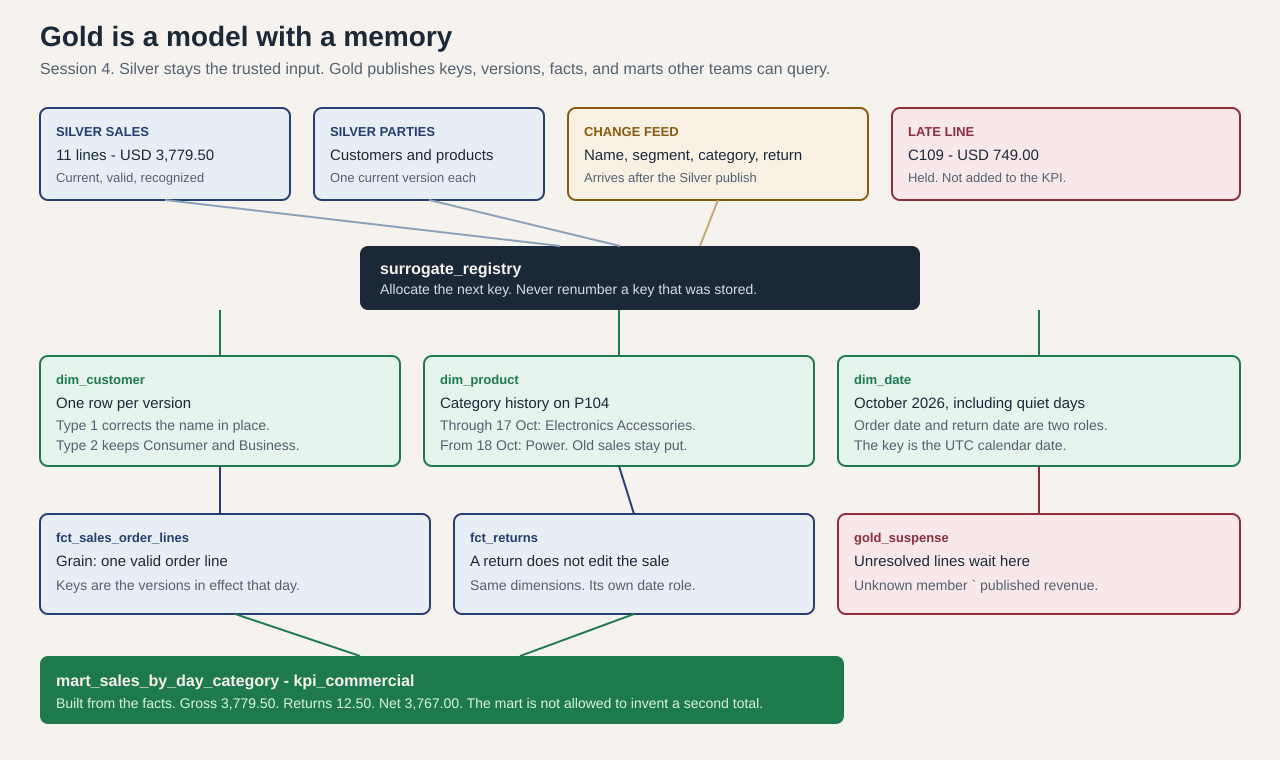

The grain is data. The notebook is not the only place it lives.


,dataset,grain
0,dim_customer,One row is one version of a customer. Type 2 add...
1,dim_date,One row is one calendar date in the published mo...
2,dim_product,One row is one version of a product. Historical ...
3,fct_returns,One row is one accepted return event. It does no...
4,fct_sales_order_lines,One row is one valid order line in its current a...
5,mart_sales_by_day_category,"One row is category revenue for one order date, ..."


The bus. Which fact uses which role of a shared dimension.


,dataset,customer_role,product_role,date_role
0,fct_returns,customer version on the return date,product version on the return date,return date; the sale date is a second role of d...
1,fct_sales_order_lines,customer version on the order date,product version on the order date,order date
2,mart_sales_by_day_category,not carried; aggregate above customer,category of the product key stored on the fact,order date


In [3]:
display(SVG(filename=str(ROOT / "docs" / "gold_dimensional_model.svg")))

show(warehouse.query('''
    SELECT dataset, grain
    FROM gold_contract
    ORDER BY dataset
'''), "The grain is data. The notebook is not the only place it lives.")

show(warehouse.query('''
    SELECT dataset, customer_role, product_role, date_role
    FROM gold_bus_matrix
    ORDER BY dataset
'''), "The bus. Which fact uses which role of a shared dimension.")


## 3. Durable keys (10 minutes)

**What we are learning.** Why the warehouse owns a key the source has never heard of, and why that key is allocated once.

**Why it matters.** Facts store the key. If tomorrow's load computes the key again from the current set of ids, every historical fact either moves or has to be rewritten.

The business key (`C100`, `P104`) is the identifier the source owns. The surrogate (`customer_key`, `product_key`) is the identifier this platform owns. Queries join facts to surrogates. The business key stays on the dimension so a person can trace a row home.

The allocator does two phases, on purpose:

1. The customers and products Silver already published, ordered by business key. On an empty registry that is `C100 = 1` through `C107 = 8`, and `P101 = 1` through `P110 = 10`.
2. Versions and parties that were not in that set. They receive `max(key) + 1`. Nobody already stored is renumbered.

`C050` (Samir Haddad) arrives on 18 October with no orders. He is in the change feed, so he is phase 2.

> **Ask the audience.** `C050` sorts before `C100`. What happens to yesterday's `customer_key` if we mint keys with `ROW_NUMBER()` over the new set?

> **Instructor note.** Expected answer: `C100` becomes 2, and every fact that stored 1 now points at a different person or at nobody. The durable key stays 1. `C050` receives 10, the next key, even though a rebuilt row number would give him 1.

> **Production consideration.** Simplified here: the registry is a table in this DuckDB file. A brand-new file still assigns `C100 = 1` because phase 1 runs before phase 2, not because row numbers are stable. The second publish, later this hour, is the proof that the keys were stored. In production the registry outlives the job, and a key is never recycled.

> **Key concept.** The unknown member is key `-1`. It gives a query a name for a missing party. It is not a customer we are allowed to book revenue against.


In [4]:
show_sql(
    "010_customer_dimension.sql",
    "-- Phase 2:",
    "CREATE OR REPLACE TABLE dim_customer",
)

show(warehouse.query('''
    SELECT customer_id, row_number_key, durable_key
    FROM cmp_original_customer_keys
    ORDER BY customer_id
'''), "The original eight. Row number and durable key match, because this is the set those numbers were computed on.")

show(warehouse.query('''
    SELECT customer_id, row_number_if_rebuilt, durable_key
    FROM cmp_fragile_customer_keys
    ORDER BY customer_id
'''), "The set plus C050. A rebuilt row number moves C100 from 1 to 2. The stored key does not move.")

expect_one(
    "SELECT durable_key FROM cmp_fragile_customer_keys WHERE customer_id = 'C100'",
    C100_KEY,
    "C100 durable key",
)
expect_one(
    "SELECT row_number_if_rebuilt FROM cmp_fragile_customer_keys WHERE customer_id = 'C100'",
    2,
    "C100 rebuilt row number",
)
expect_one(
    "SELECT durable_key FROM cmp_fragile_customer_keys WHERE customer_id = 'C050'",
    C050_KEY,
    "C050 durable key",
)
expect_one(
    "SELECT row_number_if_rebuilt FROM cmp_fragile_customer_keys WHERE customer_id = 'C050'",
    1,
    "C050 rebuilt row number",
)

show(warehouse.query('''
    SELECT customer_key, customer_id, customer_name, customer_segment, change_reason
    FROM dim_customer
    WHERE customer_key < 0 OR customer_id = 'C050'
    ORDER BY customer_key
'''), "C050 is a real member with no sales. The unknown member is a named gap, key -1.")


-- Phase 2: versions and customers that were not in that first set.
-- C101 version 2 and C050 receive the next keys. Nobody already stored moves.
CREATE OR REPLACE TEMP TABLE customer_keys_phase2 AS
SELECT
    plan.customer_id AS business_key,
    plan.version_number,
    base.max_key + ROW_NUMBER() OVER (
        ORDER BY plan.effective_from, plan.customer_id, plan.version_number
    ) AS surrogate_key
FROM customer_version_plan AS plan
CROSS JOIN (
    SELECT COALESCE(MAX(surrogate_key), 0) AS max_key
    FROM surrogate_registry
    WHERE entity_name = 'customer'
) AS base
WHERE NOT EXISTS (
    SELECT 1
    FROM surrogate_registry AS registry
    WHERE registry.entity_name = 'customer'
      AND registry.business_key = plan.customer_id
      AND registry.version_number = plan.version_number
);

INSERT INTO surrogate_registry
SELECT 'customer', business_key, version_number, surrogate_key
FROM customer_keys_phase2;

The original eight. Row number and durable key match, because this i

,customer_id,row_number_key,durable_key
0,C100,1,1
1,C101,2,2
2,C102,3,3
3,C103,4,4
4,C104,5,5
5,C105,6,6
6,C106,7,7
7,C107,8,8


The set plus C050. A rebuilt row number moves C100 from 1 to 2. The stored key does not move.


,customer_id,row_number_if_rebuilt,durable_key
0,C050,1,10
1,C100,2,1
2,C101,3,2
3,C102,4,3
4,C103,5,4
5,C104,6,5
6,C105,7,6
7,C106,8,7
8,C107,9,8


C050 is a real member with no sales. The unknown member is a named gap, key -1.


,customer_key,customer_id,customer_name,customer_segment,change_reason
0,-1,UNKNOWN,Unknown customer,Unknown,unknown_member
1,10,C050,Samir Haddad,Business,new_account


## 4. Attribute history (14 minutes)

**What we are learning.** Which changes overwrite a value, and which changes add a version the fact can still point at.

**Why it matters.** "Revenue by segment" is two questions wearing one name. Revenue by the segment at the time of the sale, and revenue by the segment the customer is in today, are both legitimate. They are not the same number. The model has to make the choice visible.

Two changes arrived after the Silver publish:

| Customer | Change | Treatment | Why |
| --- | --- | --- | --- |
| `C100` | John Smith becomes John A. Smith on 18 October | Type 1 | A corrected legal name. The previous spelling should not remain a way to slice revenue |
| `C101` | Consumer becomes Business on 17 October | Type 2 | The segment is a business state. Sales before the 17th were Consumer sales |

Type 1 updates the attribute on the existing version. There is still one row for `C100`, and the key is still 1. The October sales now display the corrected name. The previous spelling, and the date we learned about the correction, are not queryable. That is the tradeoff, chosen on purpose.

Type 2 closes the open version and appends a row. `C101` version 1 is Consumer from 1 September through 16 October. Version 2 is Business from 17 October, and it receives the next surrogate, key 9.

A sale matches a version when the order date falls inside `[effective_from, effective_to]`. An open version has no `effective_to`. The end date is inclusive. The next version starts the next day.

```sql
order_date >= effective_from
AND (effective_to IS NULL OR order_date <= effective_to)
```

Priya's phone, `OL-1002-1`, is 15 October. The fact points at key 2, Consumer. Joining onward to `is_current` points at key 9, Business, and moves **USD 1,199.00**.

> **Ask the audience.** Finance asks for revenue by the segment the customer is in today. Which join is that, and what has to happen to the column name?

> **Instructor note.** Expected answer: join the fact to the customer key, then to the row where `is_current` is true. The result is the as-is reading. It is a legal question and a different question. The published mart uses the key stored on the fact. As sold, Consumer phones are 1,948.00 and Business phones are 1,478.00. As the current segment, Consumer falls to 749.00 and Business rises to 2,677.00.

> **Ask the audience.** Why isn't every change Type 2?

> **Instructor note.** Expected answer: Type 2 would keep every spelling fix and every whitespace cleanup as a version. Facts would miss a version or fan out across two of them. Type 1 is the correction where the previous value must stop being a slice. The decision is per attribute, and it is made before the row is written.

> **Common mistake.** Treating the effective date as a timestamp we can improvise. This contract versions by calendar date. A sale and a segment change on the same morning are a case we have not been given. We do not invent a tie-break in the query.

> **Production consideration.** Simplified here: one Type 2 change, and the first version starts when this platform first trusted the Silver attribute, not on the day the customer registered. We do not backfill a history we never received. Type 3 (a previous-value column on the same row) is a different design. We are not building it.


C100 has one version and a corrected name. C101 has two versions. C107 is still the other John Smith.


,customer_key,customer_id,customer_name,customer_segment,effective_from,effective_to,is_current,version_number,change_reason
0,1,C100,John A. Smith,Consumer,2026-10-01,,True,1,initial_publish
1,2,C101,Priya Nair,Consumer,2026-09-01,2026-10-16,False,1,initial_publish
2,9,C101,Priya Nair,Business,2026-10-17,,True,2,account_upgraded
3,8,C107,John Smith,Consumer,2026-09-20,,True,1,initial_publish


Priya's phone. 15 October. The fact stored the Consumer version, key 2. USD 1,199.00.


,order_line_id,order_date_key,customer_key,customer_segment,version_number,gross_amount
0,OL-1002-1,20261015,2,Consumer,1,"1,199.00"


Smartphones only. as_was uses the key on the fact. as_is joins to the current segment. The 1,199.00 changes segment.


,reading,customer_segment,revenue
0,as_is,Business,"2,677.00"
1,as_is,Consumer,749.00
2,as_was,Business,"1,478.00"
3,as_was,Consumer,"1,948.00"


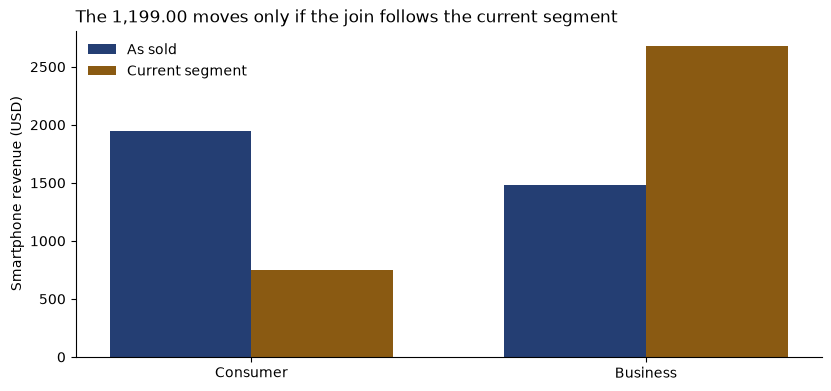

In [5]:
show(warehouse.query('''
    SELECT
        customer_key,
        customer_id,
        customer_name,
        customer_segment,
        effective_from,
        effective_to,
        is_current,
        version_number,
        change_reason
    FROM dim_customer
    WHERE customer_id IN ('C100', 'C101', 'C107')
    ORDER BY customer_id, version_number
'''), "C100 has one version and a corrected name. C101 has two versions. C107 is still the other John Smith.")

show(warehouse.query('''
    SELECT
        facts.order_line_id,
        facts.order_date_key,
        facts.customer_key,
        customers.customer_segment,
        customers.version_number,
        facts.gross_amount
    FROM fct_sales_order_lines AS facts
    JOIN dim_customer AS customers ON customers.customer_key = facts.customer_key
    WHERE facts.order_line_id = 'OL-1002-1'
'''), "Priya's phone. 15 October. The fact stored the Consumer version, key 2. USD 1,199.00.")

expect_one(
    '''
    SELECT customers.customer_segment
    FROM fct_sales_order_lines AS facts
    JOIN dim_customer AS customers ON customers.customer_key = facts.customer_key
    WHERE facts.order_line_id = 'OL-1002-1'
    ''',
    "Consumer",
    "sale segment",
)

show(warehouse.query('''
    SELECT reading, customer_segment, revenue
    FROM cmp_smartphone_segment_history
    ORDER BY reading, customer_segment
'''), "Smartphones only. as_was uses the key on the fact. as_is joins to the current segment. The 1,199.00 changes segment.")

segment = warehouse.query('''
    SELECT reading, customer_segment, revenue
    FROM cmp_smartphone_segment_history
''')
pivot = segment.pivot(index="customer_segment", columns="reading", values="revenue").fillna(0)
pivot = pivot.reindex(["Consumer", "Business"])
fig, ax = plt.subplots(figsize=(8.2, 3.8), layout="constrained")
positions = range(len(pivot.index))
width = 0.36
as_was = [float(value) for value in pivot["as_was"]]
as_is = [float(value) for value in pivot["as_is"]]
ax.bar([p - width / 2 for p in positions], as_was, width=width, color=C_SOURCE, label="As sold")
ax.bar([p + width / 2 for p in positions], as_is, width=width, color=C_WARN, label="Current segment")
ax.set_xticks(list(positions), list(pivot.index))
ax.set_ylabel("Smartphone revenue (USD)")
ax.set_title("The 1,199.00 moves only if the join follows the current segment", loc="left")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

expect_one(
    '''
    SELECT revenue FROM cmp_smartphone_segment_history
    WHERE reading = 'as_was' AND customer_segment = 'Consumer'
    ''',
    CONSUMER_PHONES_AS_WAS,
    "consumer phones as sold",
)
expect_one(
    '''
    SELECT revenue FROM cmp_smartphone_segment_history
    WHERE reading = 'as_is' AND customer_segment = 'Business'
    ''',
    BUSINESS_PHONES_AS_IS,
    "business phones as current",
)


### The same rule on the product

Merchandising moved `P104`, the USB-C adapter, from Electronics Accessories to Power on 18 October. That is a Type 2 change on category. It is a business decision with a date. It is not a new call to the model from Session 3.

Both adapter lines are dated before the 18th: 38.00 on the 15th and 76.00 on the 17th. They keep product key 4, Electronics Accessories. Key 11 is Power, and no sale points at it yet.

As sold, Electronics Accessories is **211.00**. Join those same facts to the current product and Accessories falls to **97.00**, with **114.00** sitting in Power.

> **Key concept.** The fact already holds the answer to "what category did we sell." Re-joining to today's category answers "how would we classify that sale now." Gold publishes the first. The second is a labeled comparison, `cmp_category_history`, and it is not the mart.

> **Instructor note.** Home appliances stay 89.00 and personal care stays 53.50 under both readings. Smartphones stay 3,426.00. The only category that moves is the adapter. If the room wants one number to remember, it is 114.00.


P104. Key 4 covers the sales. Key 11 is the reclass, and it has no facts yet.


,product_key,product_id,category,subcategory,enrichment_method,effective_from,effective_to,is_current,version_number
0,4,P104,Electronics Accessories,Chargers,llm,2026-10-01,2026-10-17,False,1
1,11,P104,Power,Chargers,manual,2026-10-18,,True,2


As sold against as currently classified. Power exists only on the right.


,category,as_was_revenue,as_is_revenue
0,Smartphones,"3,426.00","3,426.00"
1,Electronics Accessories,211.00,97.00
2,Home Appliances,89.00,89.00
3,Personal Care,53.50,53.50
4,Power,,114.00


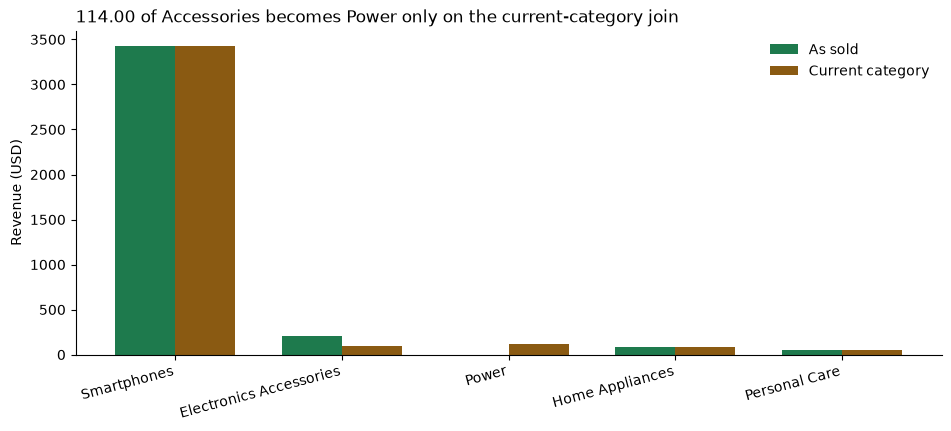

In [6]:
show(warehouse.query('''
    SELECT
        product_key,
        product_id,
        category,
        subcategory,
        enrichment_method,
        effective_from,
        effective_to,
        is_current,
        version_number
    FROM dim_product
    WHERE product_id = 'P104'
    ORDER BY version_number
'''), "P104. Key 4 covers the sales. Key 11 is the reclass, and it has no facts yet.")

show(warehouse.query('''
    SELECT category, as_was_revenue, as_is_revenue
    FROM cmp_category_history
    ORDER BY COALESCE(as_was_revenue, 0) DESC, category
'''), "As sold against as currently classified. Power exists only on the right.")

expect_one(
    "SELECT product_key FROM fct_sales_order_lines WHERE order_line_id = 'OL-1003-1'",
    P104_VERSION_1_KEY,
    "adapter fact key",
)
expect_one(
    "SELECT as_was_revenue FROM cmp_category_history WHERE category = 'Electronics Accessories'",
    ACCESSORIES_AS_WAS,
    "accessories as sold",
)
expect_one(
    "SELECT as_is_revenue FROM cmp_category_history WHERE category = 'Electronics Accessories'",
    ACCESSORIES_AS_IS,
    "accessories as current",
)
expect_one(
    "SELECT as_is_revenue FROM cmp_category_history WHERE category = 'Power'",
    POWER_AS_IS,
    "power",
)

category = warehouse.query('''
    SELECT category, as_was_revenue, as_is_revenue
    FROM cmp_category_history
''')
order = ["Smartphones", "Electronics Accessories", "Power", "Home Appliances", "Personal Care"]
category["category"] = pd.Categorical(category["category"], categories=order, ordered=True)
category = category.sort_values("category")
fig, ax = plt.subplots(figsize=(9.4, 4.2), layout="constrained")
positions = range(len(category))
width = 0.36
was = [0 if pd.isna(value) else float(value) for value in category["as_was_revenue"]]
now = [0 if pd.isna(value) else float(value) for value in category["as_is_revenue"]]
ax.bar([p - width / 2 for p in positions], was, width=width, color=C_OK, label="As sold")
ax.bar([p + width / 2 for p in positions], now, width=width, color=C_WARN, label="Current category")
ax.set_xticks(list(positions), list(category["category"]), rotation=15, ha="right")
ax.set_ylabel("Revenue (USD)")
ax.set_title("114.00 of Accessories becomes Power only on the current-category join", loc="left")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()


## 5. Facts, returns, and conformed dimensions (10 minutes)

**What we are learning.** What a fact is allowed to remember, and where a return goes.

**Why it matters.** The easy implementation updates the sale to two units, or inserts `-12.50` into the sales fact. Both make the original event unreadable. Every later consumer has to know the sign convention.

```sql
-- fct_sales_order_lines
-- one row = one valid order line
-- gross_amount = quantity * unit_price
-- the customer and product keys are the versions in effect on the order date
```

`OL-1005-1` sold 3 units of lotion on Friday 16 October, **37.50**. On Monday 19 October the customer returned 1 unit, **12.50**. The sales row is still 3 units and 37.50. `fct_returns` holds the unit that came back.

Both rows point at the same `customer_key`. Sales and returns share `dim_customer` and `dim_product`. That is what a conformed dimension is for: the next fact does not invent its own Priya, or its own lotion.

The return's date role is the return date. The sale date is a second role of the same `dim_date`. One calendar, two foreign keys.

There is a coincidence in the lotion example, and it will teach the wrong rule if we stop on it. `C103` did not change segment, so the return key equals the sale key. The scenario underneath is the case where they differ. If Priya's phone were returned on 18 October, after she became Business, the sale would stay on key 2 and the return would land on key 9. That return is not published. Subtracting it inside one segment would be a second business rule, and it would need its own name.

Three fact shapes, so the vocabulary is in the room:

| Shape | What a row records | What we did |
| --- | --- | --- |
| Transaction | An event | The sale and the return |
| Periodic snapshot | A level at a date | Units still out on the lotion line are 2. Derivable, so we did not store another fact |
| Accumulating | Milestones of one process | Pending and shipped stayed out in Session 3. They are not columns on this fact |

> **Ask the audience.** A return arrives. Do we update the sale, insert a negative sale, or insert a return fact?

> **Instructor note.** Expected answer: insert a return fact. Updating the sale destroys the three units that were sold. A negative row in the sales fact makes every query remember a sign. The return fact has its own grain, its own date, and a check: the quantity cannot exceed the sale, and the amount has to equal quantity times the sale's unit price.

> **Ask the audience.** `C109` bought a phone for 749.00 and the customer row has not arrived. Do we book it on the unknown member?

> **Instructor note.** Expected answer: no. The line waits in `gold_suspense` with reason `unknown_customer`. The unknown member lets a query name the gap. Recognized revenue still requires a real customer and a real product. The KPI stays 3,779.50. When `C109` arrives, moving the line onto a real key is a restatement, and a restatement is a release. This build does not do it quietly.

> **Common mistake.** Copying the sale's customer key onto the return. The return takes the version in effect on the return date. The lotion happens to match. The scenario is there so the match is not mistaken for the rule.


In [7]:
show_sql(
    "040_facts.sql",
    "-- fct_sales_order_lines",
    "-- A return is its own fact.",
)

show(warehouse.query('''
    SELECT
        'sale' AS event,
        facts.customer_key,
        facts.product_key,
        dates.full_date AS event_date,
        facts.quantity,
        facts.gross_amount AS amount
    FROM fct_sales_order_lines AS facts
    JOIN dim_date AS dates ON dates.date_key = facts.order_date_key
    WHERE facts.order_line_id = 'OL-1005-1'
    UNION ALL
    SELECT
        'return',
        returns.customer_key,
        returns.product_key,
        dates.full_date,
        returns.quantity,
        returns.return_amount
    FROM fct_returns AS returns
    JOIN dim_date AS dates ON dates.date_key = returns.return_date_key
    WHERE returns.order_line_id = 'OL-1005-1'
'''), "One sale, one return, one customer key. The sale still shows three units.")

show(warehouse.query('''
    SELECT
        sale_day.full_date AS sale_date,
        sale_day.day_of_week AS sale_day,
        return_day.full_date AS return_date,
        return_day.day_of_week AS return_day,
        returns.quantity,
        returns.return_amount
    FROM fct_returns AS returns
    JOIN dim_date AS sale_day ON sale_day.date_key = returns.sale_date_key
    JOIN dim_date AS return_day ON return_day.date_key = returns.return_date_key
'''), "Two roles of dim_date. Sold on Friday, returned on Monday.")

show(warehouse.query('''
    SELECT
        order_line_id,
        sale_customer_key,
        sale_segment,
        return_customer_key,
        return_segment,
        gross_amount
    FROM scenario_c101_phone_return
'''), "Not a published return. Priya's phone, if it came back on 18 October, would hit the Business version.")

expect_one("SELECT sale_customer_key FROM scenario_c101_phone_return", C101_VERSION_1_KEY, "scenario sale key")
expect_one("SELECT return_customer_key FROM scenario_c101_phone_return", C101_VERSION_2_KEY, "scenario return key")
expect_one("SELECT gross_amount FROM scenario_c101_phone_return", C101_PHONE, "scenario amount")
expect_one("SELECT COUNT(*) FROM fct_returns WHERE order_line_id = 'OL-1002-1'", 0, "scenario was not posted")

show(warehouse.query('''
    SELECT order_line_id, order_id, customer_id, product_id, event_date, amount, reason
    FROM gold_suspense
    ORDER BY order_line_id
'''), "Suspense. C109's 749.00 is real money and it is not recognized revenue.")

expect_one(
    "SELECT COALESCE(SUM(amount), 0) FROM gold_suspense WHERE reason = 'unknown_customer'",
    SUSPENSE_AMOUNT,
    "suspense",
)
expect_one("SELECT CAST(SUM(gross_amount) AS DECIMAL(12, 2)) FROM fct_sales_order_lines", GROSS_SALES, "gross unchanged")


-- fct_sales_order_lines
-- Grain: one current, valid, recognized-revenue order line.
-- The foreign keys are the dimension versions in effect on the order date.
-- gross_amount is quantity * unit_price. This fact does not store returns.

CREATE OR REPLACE TABLE fct_sales_order_lines AS
SELECT
    sales.order_line_id,
    sales.order_id,
    customers.customer_key,
    products.product_key,
    dates.date_key AS order_date_key,
    sales.quantity,
    sales.unit_price,
    sales.gross_amount,
    sales.currency
FROM silver_sales AS sales
JOIN dim_customer AS customers
  ON customers.customer_id = sales.customer_id
 AND version_covers(customers.effective_from, customers.effective_to, sales.order_date)
JOIN dim_product AS products
  ON products.product_id = sales.product_id
 AND version_covers(products.effective_from, products.effective_to, sales.order_date)
JOIN dim_date AS dates
  ON dates.full_date = sales.order_date;

One sale, one return, one customer key. The sale still shows three

,event,customer_key,product_key,event_date,quantity,amount
0,sale,4,5,2026-10-16,3,37.50
1,return,4,5,2026-10-19,1,12.50


Two roles of dim_date. Sold on Friday, returned on Monday.


,sale_date,sale_day,return_date,return_day,quantity,return_amount
0,2026-10-16,Friday,2026-10-19,Monday,1,12.50


Not a published return. Priya's phone, if it came back on 18 October, would hit the Business version.


,order_line_id,sale_customer_key,sale_segment,return_customer_key,return_segment,gross_amount
0,OL-1002-1,2,Consumer,9,Business,"1,199.00"


Suspense. C109's 749.00 is real money and it is not recognized revenue.


,order_line_id,order_id,customer_id,product_id,event_date,amount,reason
0,OL-1026-1,ORD-1026,C109,P101,2026-10-18,749.00,unknown_customer


## 6. Marts and the KPI (8 minutes)

**What we are learning.** A stored aggregate is still a query, and it has one job: agree with the fact.

**Why it matters.** The executive dashboard will not scan 11 lines, and next year it will not scan the line-level fact either. The moment the mart is loaded by a second pipeline, with its own join to "current category," the company has two revenues.

`mart_sales_by_day_category` groups the sales fact by the order date and by the category on the product key stored on the fact. It uses the as-sold category. Its sum is **3,779.50**.

`kpi_commercial` is one row:

| Measure | Definition | Value |
| --- | --- | --- |
| Gross sales | Sum of the sales fact | 3,779.50 |
| Returns | Sum of the return fact | 12.50 |
| Net sales | Gross minus returns, company level | 3,767.00 |
| Orders | Distinct `order_id` on the sales fact | 10 |
| Average order gross | Gross divided by orders, not by lines, and not net of returns | 377.95 |
| Weekend | Saturday 17 October plus Sunday 18 October | 889.00 |

Net by segment is not in this KPI. The scenario showed why: a sale can sit on Consumer while a return sits on Business. Company-level net does not require that rule. Segment-level net would, and we have not published it.

> **Ask the audience.** The daily mart and a dashboard both claim to be Gold, and they disagree by 114.00. Which one is wrong?

> **Instructor note.** Expected answer: the one that is not derived from the fact, until someone shows the fact itself is wrong. A dashboard joined to the current product category is the as-is reading. It can be shown. It does not replace `mart_sales_by_day_category`.

> **Common mistake.** Building the mart from Silver, or from the current dimension, "because it is faster." It is faster until the definitions diverge. The reconciliation query is the test: `SUM(mart) = SUM(fact)`.

> **Production consideration.** Simplified here: the mart is rebuilt in full, in the same database, every publish. An incremental mart has to delete and replace the dates the run touched, or it will double. Session 5 owns that design. This hour only requires the equality.


The mart. One row per order date and as-sold category. 1 October is in dim_date and absent here.


,order_date,day_of_week,is_weekend,category,gross_amount,units
0,2026-10-15,Thursday,False,Electronics Accessories,87.00,3
1,2026-10-15,Thursday,False,Smartphones,"1,948.00",2
2,2026-10-16,Friday,False,Home Appliances,89.00,1
3,2026-10-16,Friday,False,Personal Care,37.50,3
4,2026-10-16,Friday,False,Smartphones,729.00,1
5,2026-10-17,Saturday,True,Electronics Accessories,124.00,6
6,2026-10-17,Saturday,True,Personal Care,16.00,1
7,2026-10-18,Sunday,True,Smartphones,749.00,1


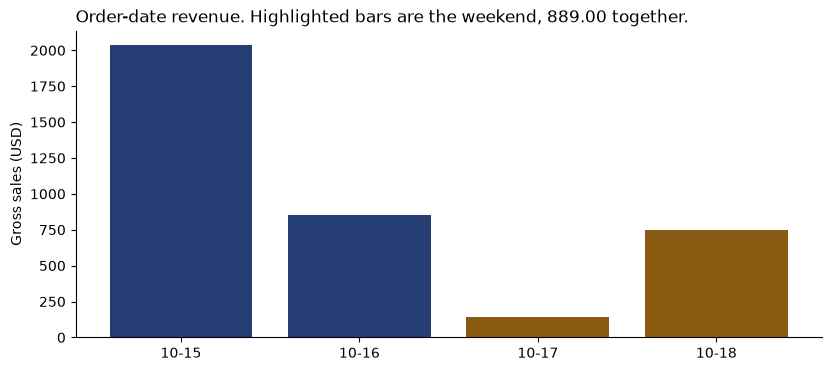

One commercial KPI. Net subtracts the return once, at company level.

,gross_sales,return_amount,net_sales,order_count,line_count,units_sold,units_returned,average_order_gross
0,"3,779.50",12.50,"3,767.00",10,11,18,1,377.95


Mart sum equals fact sum: 3779.50


In [8]:
show(warehouse.query('''
    SELECT order_date, day_of_week, is_weekend, category, gross_amount, units
    FROM mart_sales_by_day_category
    ORDER BY order_date, category
'''), "The mart. One row per order date and as-sold category. 1 October is in dim_date and absent here.")

daily = warehouse.query('''
    SELECT order_date, BOOL_OR(is_weekend) AS is_weekend, SUM(gross_amount) AS gross_amount
    FROM mart_sales_by_day_category
    GROUP BY order_date
    ORDER BY order_date
''')
fig, ax = plt.subplots(figsize=(8.2, 3.6), layout="constrained")
colors = [C_WARN if flag else C_SOURCE for flag in daily["is_weekend"]]
labels = [pd.Timestamp(value).strftime("%m-%d") for value in daily["order_date"]]
bars = ax.bar(labels, [float(value) for value in daily["gross_amount"]], color=colors)
ax.set_ylabel("Gross sales (USD)")
ax.set_title("Order-date revenue. Highlighted bars are the weekend, 889.00 together.", loc="left")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

show(warehouse.query("SELECT * FROM kpi_commercial"), "One commercial KPI. Net subtracts the return once, at company level.")

expect_one("SELECT COALESCE(SUM(gross_amount), 0) FROM mart_sales_by_day_category", GROSS_SALES, "mart reconciles")
expect_one("SELECT COALESCE(SUM(gross_amount), 0) FROM mart_sales_by_day_category WHERE is_weekend", WEEKEND_GROSS, "weekend")
expect_one("SELECT net_sales FROM kpi_commercial", NET_SALES, "net")
expect_one("SELECT return_amount FROM kpi_commercial", RETURN_AMOUNT, "returns")
print("Mart sum equals fact sum:", GROSS_SALES)


## 7. Run it again (6 minutes)

**What we are learning.** What a second publish is allowed to change.

**Why it matters.** A pipeline that appends a second copy of October, or that allocates a new key for `C100` because the job restarted, will look healthy in the logs and wrong in the report.

The second publish reloads Silver and the change feed, runs the same SQL, and does not reset the registry. Facts and dimensions are replaced. Registry rows are inserted only when the business key and the version are absent.

> **Ask the audience.** The transformation runs twice. What should be true afterward?

> **Instructor note.** Expected answer: the same 11 lines, the same keys, the same gross, the same net. `C101` still has two versions, not four. The registry still has 21 rows. Nothing in the publish reads the clock, so a rerun does not mint a version from "now."

> **Production consideration.** Simplified here: replace the tables. A production run also records which publish produced the row, and a failed run leaves the previous publish queryable. Session 6 owns that boundary. The property we require today is smaller and stricter: running it again is not allowed to invent a second history.


In [9]:
second = warehouse.build(reset_registry=False)
if warehouse.signature() != FIRST_SIGNATURE:
    raise AssertionError("The second publish changed a key, a version, or an amount.")
if second["registry_rows"] != 21:
    raise AssertionError("The registry grew on the second publish: " + str(second["registry_rows"]) + ".")
if second["gross_sales"] != GROSS_SALES or second["net_sales"] != NET_SALES:
    raise AssertionError("Gross or net moved on the second publish.")

print("Second publish matches the first.")
print("Registry rows:", second["registry_rows"])
print("Gross", second["gross_sales"], "Returns", second["return_amount"], "Net", second["net_sales"])
print("Lines", second["fact_rows"], "Suspense rows", second["suspense_rows"])
print("Silver source:", second["silver_origin"])


Second publish matches the first.
Registry rows: 21
Gross 3779.50 Returns 12.50 Net 3767.00
Lines 11 Suspense rows 1
Silver source: checked_in_silver


## What this hour was for

Gold is the layer that can be queried without reading the pipeline. It earns that by stating the grain, by keeping a key that survives the next customer, and by pointing each event at the attribute version that was true that day.

A return, a reclass, and a late line each have a place to land. None of them is allowed to silently become a new definition of the 3,779.50.

The next hour takes this model off a full rebuild: what incremental processing has to recompute, what it must leave alone, and which monitors tell you the publish is no longer the one you certified.
